# Atlas-DeePC control-parameter ablation: $\lambda_g$

This notebook isolates the coefficient regularization weight `lam_g` in the baseline graph-routed Atlas-DeePC controller from `baseline_graph_routed_atlas_deepc.ipynb`. It evaluates the exact same **500 seeds, 211–710**, at $\lambda_g=0$, 50 log-spaced positive values from $10^{-2}$ through $10^2$, and the exact baseline value $\lambda_g=0.05$.

Only `lam_g` changes. The offline Hankel library, frozen 48-chart physical-configuration atlas, chart assignments, transition graph, goal construction, waypoint routing, QP weights and constraints, rollout length, and strict-success definition remain fixed. The sweep is paired by seed, resumable after every rollout, and stores compact summaries instead of trajectories.

In [1]:
import importlib
import json
import math
import os
import sys
from dataclasses import asdict
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

import control_parameter_ablation as ablation
import routed_deepc_experiment as experiment
ablation = importlib.reload(ablation)

DATA_PATH = ROOT / "data" / "select_iid_offline_hankel.npy"
RESULT_ROOT = ROOT / "experiments" / "routed_deepc_iid"
BASELINE_DIR = RESULT_ROOT / "clustering_jointconfig48_fresh211_310"
OUTPUT_ROOT = RESULT_ROOT / "ablation_control_parameter_lam_g_500"
ZERO_OUTPUT_ROOT = RESULT_ROOT / "ablation_control_parameter_lam_g_zero_500"

for path in (DATA_PATH, BASELINE_DIR / "summary.json", BASELINE_DIR / "behavioral_atlas.npz"):
    assert path.exists(), path
print("Project root:", ROOT)

Project root: /Users/kumiko/Projects/atlas_deepc_reacher


## 1. Controlled sweep design

The baseline DeePC objective includes $\lambda_g\lVert g\rVert_2^2$. A small value gives the local behavioral coefficients more freedom; a large value shrinks them more strongly. Because the 500 environment seeds are identical at every value, changes can be analyzed as paired outcomes rather than independent panels.

The exact baseline value is added explicitly because it is not one of the 50 points returned by `np.logspace(-2, 2, 50)`. The zero-regularization endpoint is also evaluated separately because it cannot be represented on a logarithmic grid. Thus the controlled sweep contains 52 values and 26,000 rollouts.

In [2]:
LOG_GRID_SIZE = 50
EVALUATION_SEEDS = list(range(211, 711))  # Exactly 500 seeds; stop is exclusive.
RUN_EXPERIMENTS = True  # Set False when you only want to re-open and analyze saved results.
WORKERS = min(6, os.cpu_count() or 1)
OVERWRITE = False

baseline_payload = json.loads((BASELINE_DIR / "summary.json").read_text())
BASE_CONFIG = experiment.RoutedDeePCConfig(**baseline_payload["config"])
BASELINE_LAM_G = float(BASE_CONFIG.lam_g)
POSITIVE_LAM_G_VALUES = np.unique(np.r_[np.logspace(-2, 2, LOG_GRID_SIZE), BASELINE_LAM_G])
POSITIVE_LAM_G_VALUES.sort()
LAM_G_VALUES = np.r_[0.0, POSITIVE_LAM_G_VALUES]
atlas = experiment.load_atlas(BASELINE_DIR / "behavioral_atlas.npz")

assert EVALUATION_SEEDS == list(range(211, 711))
assert len(EVALUATION_SEEDS) == len(set(EVALUATION_SEEDS)) == 500
assert len(POSITIVE_LAM_G_VALUES) == LOG_GRID_SIZE + 1
assert len(LAM_G_VALUES) == LOG_GRID_SIZE + 2
assert LAM_G_VALUES[0] == 0.0
assert np.any(LAM_G_VALUES == BASELINE_LAM_G)
assert BASE_CONFIG.clusters == 48
assert BASE_CONFIG.clustering_method == "minibatch_kmeans"
assert BASE_CONFIG.clustering_feature_mode == "plant_joint_configuration"
assert BASE_CONFIG.formulation == "svd_current"

display(pd.Series({
    "parameter": "lam_g",
    "baseline value": BASELINE_LAM_G,
    "log-grid values": LOG_GRID_SIZE,
    "total parameter values": len(LAM_G_VALUES),
    "parameter range": f"{LAM_G_VALUES.min():.2e} to {LAM_G_VALUES.max():.2e}",
    "seed range": f"{EVALUATION_SEEDS[0]}-{EVALUATION_SEEDS[-1]}",
    "seeds per value": len(EVALUATION_SEEDS),
    "total rollouts": len(LAM_G_VALUES) * len(EVALUATION_SEEDS),
    "parallel workers": WORKERS,
    "frozen atlas charts": atlas["centers"].shape[0],
}))
display(pd.DataFrame({"index": np.arange(len(LAM_G_VALUES)), "lam_g": LAM_G_VALUES}).style.format({"lam_g": "{:.8g}"}))

parameter                                lam_g
baseline value                            0.05
log-grid values                             50
total parameter values                      52
parameter range           0.00e+00 to 1.00e+02
seed range                             211-710
seeds per value                            500
total rollouts                           26000
parallel workers                             6
frozen atlas charts                         48
dtype: object

,index,lam_g
0,0,0
1,1,0.01
2,2,0.012067926
3,3,0.014563485
4,4,0.017575106
5,5,0.021209509
6,6,0.025595479
7,7,0.030888436
8,8,0.037275937
9,9,0.044984327


## 2. Run or resume the sweep

`RUN_EXPERIMENTS` defaults to `True` for the requested study. Six workers require roughly 12–14 hours at the baseline's observed solve time, although machine load and extreme parameter values can change this estimate. Every finished rollout is appended to a compact JSONL checkpoint; rerunning the cell with `OVERWRITE=False` resumes only missing seeds. Set `RUN_EXPERIMENTS=False` when you only want to reopen and analyze saved results.

The fixed chart matrices are constructed once per worker and reused for all values. Existing baseline rollouts are deliberately not borrowed because older caches do not contain the closed-loop cost fields required here.

In [3]:
if RUN_EXPERIMENTS:
    sweep_manifest = ablation.run_lam_g_sweep(
        POSITIVE_LAM_G_VALUES,
        EVALUATION_SEEDS,
        BASELINE_DIR,
        OUTPUT_ROOT,
        DATA_PATH,
        workers=WORKERS,
        overwrite=OVERWRITE,
    )
    zero_manifest = ablation.run_lam_g_sweep(
        [0.0],
        EVALUATION_SEEDS,
        BASELINE_DIR,
        ZERO_OUTPUT_ROOT,
        DATA_PATH,
        workers=WORKERS,
        overwrite=OVERWRITE,
    )
    print("Positive sweep complete:", sweep_manifest["complete"])
    print("Zero endpoint complete:", zero_manifest["complete"])
else:
    print(
        f"Dry run: set RUN_EXPERIMENTS=True to run or resume "
        f"{len(LAM_G_VALUES) * len(EVALUATION_SEEDS):,} rollouts."
    )

lam_g=0.01 | saved=500 | pending=0


completed lam_g=0.01: 500/500 saved


lam_g=0.012067926 | saved=500 | pending=0


completed lam_g=0.012067926: 500/500 saved


lam_g=0.014563485 | saved=500 | pending=0


completed lam_g=0.014563485: 500/500 saved


... (95 outputs left out)

completed lam_g=100: 500/500 saved


lam_g=0 | saved=500 | pending=0


completed lam_g=0: 500/500 saved


Positive sweep complete: True
Zero endpoint complete: True


## 3. Completion and controlled-change audit

A value is marked complete only when it contains all 500 unique seeds in the requested order and its saved configuration differs from the baseline only in `lam_g`. Partial values remain resumable but are excluded from the default performance plot to avoid comparing different seed panels.

In [4]:
manifest_path = OUTPUT_ROOT / "manifest.json"
zero_manifest_path = ZERO_OUTPUT_ROOT / "manifest.json"
payloads = {}
if manifest_path.exists():
    manifest, payloads = ablation.load_lam_g_sweep(OUTPUT_ROOT)
if zero_manifest_path.exists():
    zero_manifest, zero_payloads = ablation.load_lam_g_sweep(ZERO_OUTPUT_ROOT)
    payloads.update(zero_payloads)

completion_rows = []
valid_payloads = {}
for lam_g in LAM_G_VALUES:
    payload = payloads.get(float(lam_g))
    if payload is None:
        completion_rows.append({"lam_g": lam_g, "saved": 0, "missing": 500, "valid": False, "complete": False})
        continue
    rows = payload.get("results", [])
    saved_seeds = [int(row["seed"]) for row in rows]
    expected_config = {**asdict(BASE_CONFIG), "lam_g": float(lam_g)}
    controlled_keys = set(expected_config) - {"lam_g", "seed"}
    controlled_change_valid = all(payload["config"].get(key) == expected_config[key] for key in controlled_keys)
    parameter_valid = np.isclose(payload["config"]["lam_g"], lam_g, rtol=0, atol=0)
    rows_valid = (
        len(saved_seeds) == len(set(saved_seeds))
        and all(np.isclose(row["lam_g"], lam_g, rtol=0, atol=0) for row in rows)
        and saved_seeds == [seed for seed in EVALUATION_SEEDS if seed in set(saved_seeds)]
    )
    valid = controlled_change_valid and parameter_valid and rows_valid
    complete = valid and saved_seeds == EVALUATION_SEEDS and bool(payload.get("complete"))
    completion_rows.append({
        "lam_g": lam_g, "saved": len(saved_seeds),
        "missing": len(EVALUATION_SEEDS) - len(saved_seeds),
        "valid": valid, "complete": complete,
    })
    if valid:
        valid_payloads[float(lam_g)] = payload

completion = pd.DataFrame(completion_rows)
display(completion.style.format({"lam_g": "{:.8g}"}))
complete_values = completion.loc[completion["complete"], "lam_g"].to_numpy()
print(f"Complete parameter values: {len(complete_values)}/{len(LAM_G_VALUES)}")
if not manifest_path.exists() or not zero_manifest_path.exists():
    print("One or more sweep manifests are missing. Run Section 2 first.")

,lam_g,saved,missing,valid,complete
0,0,500,0,True,True
1,0.01,500,0,True,True
2,0.012067926,500,0,True,True
3,0.014563485,500,0,True,True
4,0.017575106,500,0,True,True
5,0.021209509,500,0,True,True
6,0.025595479,500,0,True,True
7,0.030888436,500,0,True,True
8,0.037275937,500,0,True,True
9,0.044984327,500,0,True,True


Complete parameter values: 52/52


## 4. Performance over $\lambda_g$

The primary cost is the realized closed-loop cost against each seed's common final graph-compatible goal, $\sum_t (y_t-r_\mathrm{goal})^TQ(y_t-r_\mathrm{goal})+u_t^TRu_t$. The dotted curve reports cost against the controller's active graph waypoint/reference and is a routing diagnostic. Because costs and errors are skewed, curves show medians with interquartile bands.

Strict success requires both saved conditions: final-30 and final-100 mean distance below 10 mm and maximum distance below 20 mm. Success-rate bands are 95% Wilson intervals. Extra panels show final-100 error, one-step XY prediction error, usable solver status, and end-to-end control computation time.

In [5]:
def strict_success(row):
    return bool(row["success_30"] and row["success_100"])

def wilson_interval(successes, trials, z=1.959963984540054):
    rate = successes / trials
    denominator = 1 + z * z / trials
    center = (rate + z * z / (2 * trials)) / denominator
    half_width = z * np.sqrt(rate * (1 - rate) / trials + z * z / (4 * trials**2)) / denominator
    return center - half_width, center + half_width

records = []
for lam_g, payload in valid_payloads.items():
    for row in payload["results"]:
        usable_solves = int(row["statuses"].get("optimal", 0) + row["statuses"].get("optimal_inaccurate", 0))
        records.append({
            "lam_g": lam_g,
            "seed": int(row["seed"]),
            "strict success": strict_success(row),
            "final-goal cost": row["closed_loop_final_goal_cost"],
            "active-reference cost": row["closed_loop_reference_cost"],
            "final-100 mean (mm)": 1000 * row["mean_last_100"],
            "prediction error (mm)": 1000 * row["mean_prediction_error_xy"],
            "usable solve fraction": usable_solves / BASE_CONFIG.steps,
            "median control time (ms)": row["median_control_compute_time_ms"],
        })
results = pd.DataFrame(records)

summary_rows = []
if not results.empty:
    for lam_g, subset in results.groupby("lam_g", sort=True):
        successes = int(subset["strict success"].sum())
        ci_low, ci_high = wilson_interval(successes, len(subset))
        summary_rows.append({
            "lam_g": lam_g, "seeds": len(subset), "successes": successes,
            "success rate": successes / len(subset), "CI low": ci_low, "CI high": ci_high,
            "final-goal cost q25": subset["final-goal cost"].quantile(0.25),
            "final-goal cost median": subset["final-goal cost"].median(),
            "final-goal cost q75": subset["final-goal cost"].quantile(0.75),
            "active-reference cost median": subset["active-reference cost"].median(),
            "final-100 q25 (mm)": subset["final-100 mean (mm)"].quantile(0.25),
            "final-100 median (mm)": subset["final-100 mean (mm)"].median(),
            "final-100 q75 (mm)": subset["final-100 mean (mm)"].quantile(0.75),
            "prediction error median (mm)": subset["prediction error (mm)"].median(),
            "usable solve rate": subset["usable solve fraction"].mean(),
            "control time median (ms)": subset["median control time (ms)"].median(),
        })
aggregate = pd.DataFrame(summary_rows).sort_values("lam_g") if summary_rows else pd.DataFrame()
if not aggregate.empty:
    display(aggregate.style.format({
        "lam_g": "{:.8g}", "success rate": "{:.1%}", "CI low": "{:.1%}", "CI high": "{:.1%}",
        "usable solve rate": "{:.2%}", "final-goal cost median": "{:.5g}",
        "final-100 median (mm)": "{:.3f}", "prediction error median (mm)": "{:.3f}",
        "control time median (ms)": "{:.2f}",
    }))
else:
    print("No valid results are available yet.")

,lam_g,seeds,successes,success rate,CI low,CI high,final-goal cost q25,final-goal cost median,final-goal cost q75,active-reference cost median,final-100 q25 (mm),final-100 median (mm),final-100 q75 (mm),prediction error median (mm),usable solve rate,control time median (ms)
0,0,500,443,88.6%,85.5%,91.1%,195611.260208,3.6696e+05,541785.894129,113820.997340,1.332012,2.160,3.549186,1.720,100.00%,42.24
1,0.01,500,443,88.6%,85.5%,91.1%,195599.677654,3.67e+05,538862.281012,113849.724957,1.329546,2.163,3.546068,1.719,100.00%,38.84
2,0.012067926,500,443,88.6%,85.5%,91.1%,195597.301299,3.6701e+05,538861.080657,113855.672850,1.329592,2.163,3.547233,1.717,100.00%,37.36
3,0.014563485,500,443,88.6%,85.5%,91.1%,195594.442031,3.6701e+05,538871.305164,113862.853785,1.328433,2.165,3.548309,1.717,100.00%,37.10
4,0.017575106,500,443,88.6%,85.5%,91.1%,195591.003800,3.6702e+05,538883.769308,113871.524041,1.328069,2.169,3.547328,1.717,100.00%,42.87
5,0.021209509,500,443,88.6%,85.5%,91.1%,195586.872403,3.6704e+05,538898.281681,113881.993593,1.327864,2.172,3.546173,1.716,100.00%,47.62
6,0.025595479,500,443,88.6%,85.5%,91.1%,195581.912459,3.6705e+05,538915.890618,113894.637382,1.328003,2.175,3.543018,1.716,100.00%,49.64
7,0.030888436,500,443,88.6%,85.5%,91.1%,195575.964232,3.6707e+05,538937.009004,113909.910459,1.328698,2.179,3.538006,1.715,100.00%,55.17
8,0.037275937,500,443,88.6%,85.5%,91.1%,195568.840040,3.671e+05,538963.198086,113928.362629,1.330368,2.174,3.532046,1.714,100.00%,39.64
9,0.044984327,500,443,88.6%,85.5%,91.1%,195560.320919,3.6712e+05,538994.566497,113950.658811,1.332591,2.168,3.528611,1.714,100.00%,38.96


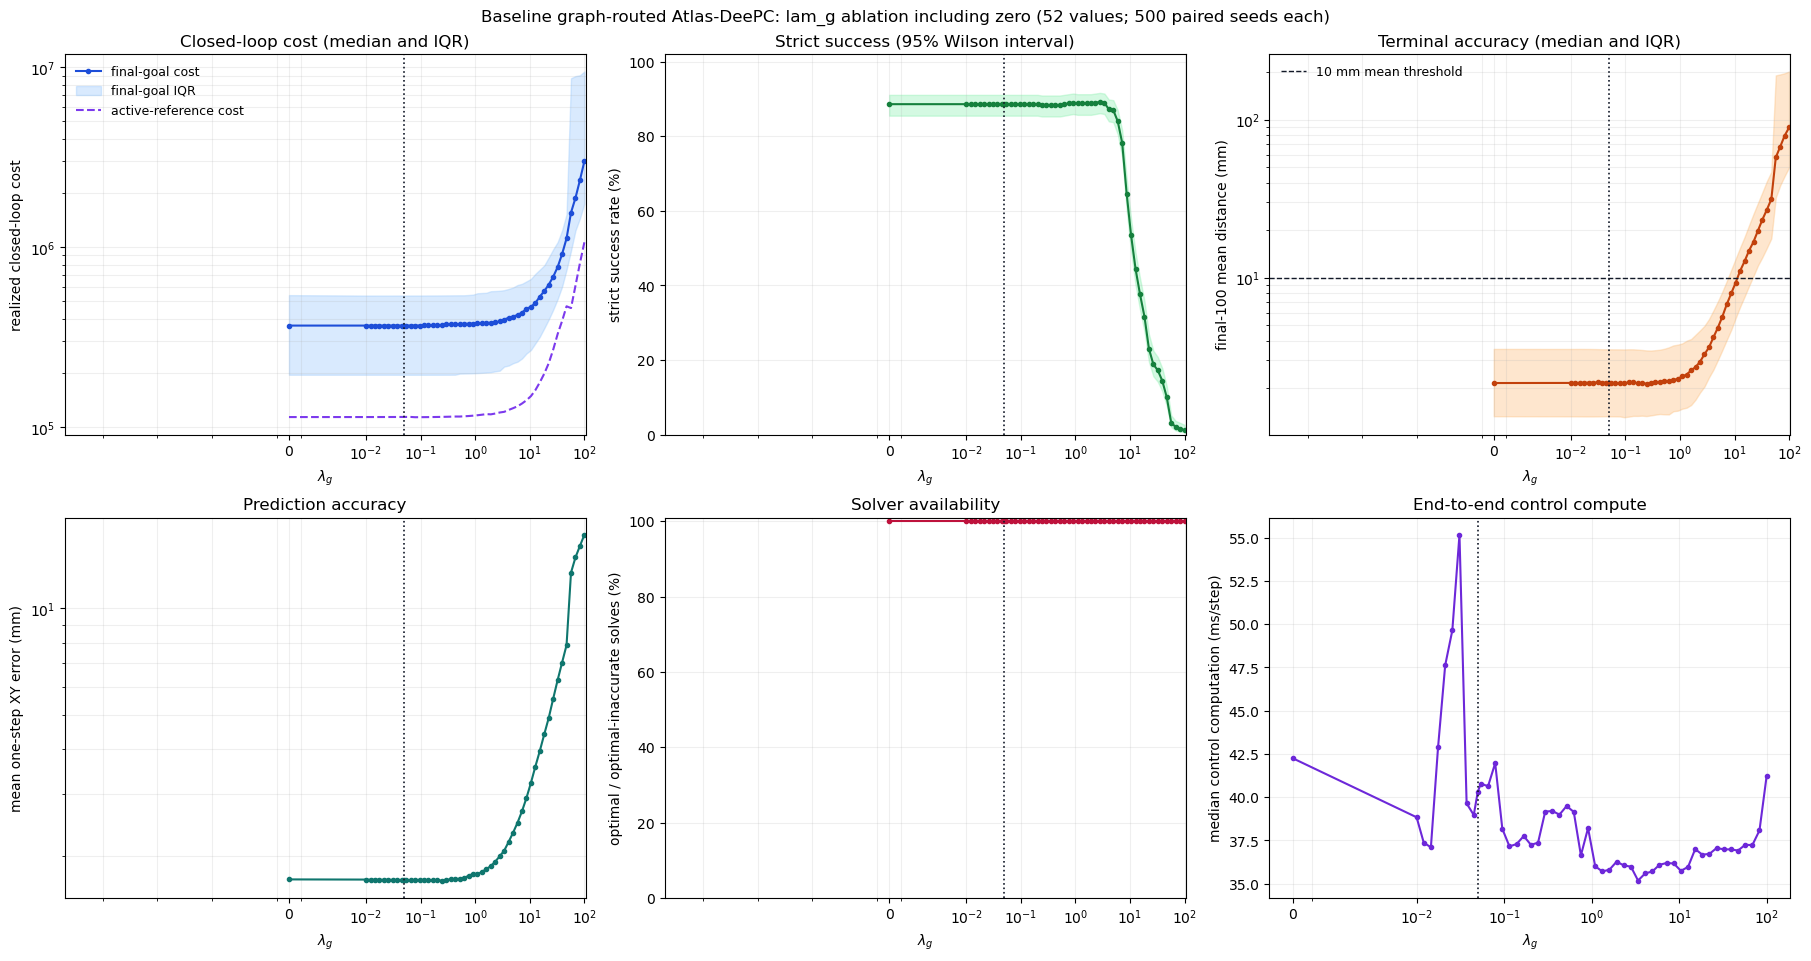

Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/ablation_control_parameter_lam_g_500/lam_g_ablation_performance.png
Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/ablation_control_parameter_lam_g_500/lam_g_ablation_summary.csv


In [6]:
if not aggregate.empty:
    plot_values = set(float(value) for value in complete_values)
    plot_data = aggregate[aggregate["lam_g"].isin(plot_values)].copy()
    if plot_data.empty:
        plot_data = aggregate.copy()
        print("WARNING: no complete lambda panel exists; plotting partial panels with seed counts shown in the table above.")
    x = plot_data["lam_g"].to_numpy()
    fig, axes = plt.subplots(2, 3, figsize=(18, 9.5), constrained_layout=True)

    axes[0, 0].plot(x, plot_data["final-goal cost median"], marker="o", ms=3, color="#1d4ed8", label="final-goal cost")
    axes[0, 0].fill_between(x, plot_data["final-goal cost q25"], plot_data["final-goal cost q75"], color="#93c5fd", alpha=0.35, label="final-goal IQR")
    axes[0, 0].plot(x, plot_data["active-reference cost median"], color="#7c3aed", linestyle="--", label="active-reference cost")
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_ylabel("realized closed-loop cost")
    axes[0, 0].set_title("Closed-loop cost (median and IQR)")
    axes[0, 0].legend(frameon=False, fontsize=9)

    axes[0, 1].plot(x, 100 * plot_data["success rate"], marker="o", ms=3, color="#15803d")
    axes[0, 1].fill_between(x, 100 * plot_data["CI low"], 100 * plot_data["CI high"], color="#86efac", alpha=0.35)
    axes[0, 1].set_ylim(0, 102)
    axes[0, 1].set_ylabel("strict success rate (%)")
    axes[0, 1].set_title("Strict success (95% Wilson interval)")

    axes[0, 2].plot(x, plot_data["final-100 median (mm)"], marker="o", ms=3, color="#c2410c")
    axes[0, 2].fill_between(x, plot_data["final-100 q25 (mm)"], plot_data["final-100 q75 (mm)"], color="#fdba74", alpha=0.35)
    axes[0, 2].axhline(10, color="#111827", linestyle="--", linewidth=1, label="10 mm mean threshold")
    axes[0, 2].set_yscale("log")
    axes[0, 2].set_ylabel("final-100 mean distance (mm)")
    axes[0, 2].set_title("Terminal accuracy (median and IQR)")
    axes[0, 2].legend(frameon=False, fontsize=9)

    axes[1, 0].plot(x, plot_data["prediction error median (mm)"], marker="o", ms=3, color="#0f766e")
    axes[1, 0].set_yscale("log")
    axes[1, 0].set_ylabel("mean one-step XY error (mm)")
    axes[1, 0].set_title("Prediction accuracy")

    axes[1, 1].plot(x, 100 * plot_data["usable solve rate"], marker="o", ms=3, color="#be123c")
    axes[1, 1].set_ylim(0, 101)
    axes[1, 1].set_ylabel("optimal / optimal-inaccurate solves (%)")
    axes[1, 1].set_title("Solver availability")

    axes[1, 2].plot(x, plot_data["control time median (ms)"], marker="o", ms=3, color="#6d28d9")
    axes[1, 2].set_ylabel("median control computation (ms/step)")
    axes[1, 2].set_title("End-to-end control compute")

    symlog_threshold = 0.5 * POSITIVE_LAM_G_VALUES.min()
    lam_g_ticks = [0.0, 0.01, 0.1, 1.0, 10.0, 100.0]
    lam_g_ticklabels = ["0", r"$10^{-2}$", r"$10^{-1}$", r"$10^0$", r"$10^1$", r"$10^2$"]
    for axis in axes.flat:
        axis.set_xscale("symlog", linthresh=symlog_threshold, linscale=1.0)
        axis.set_xticks(lam_g_ticks)
        axis.set_xticklabels(lam_g_ticklabels)
        axis.set_xlabel(r"$\lambda_g$")
        axis.axvline(BASELINE_LAM_G, color="#111827", linestyle=":", linewidth=1.2)
        axis.grid(alpha=0.2, which="both")
    fig.suptitle(f"Baseline graph-routed Atlas-DeePC: lam_g ablation including zero ({len(plot_data)} values; 500 paired seeds each)")
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    figure_path = OUTPUT_ROOT / "lam_g_ablation_performance.png"
    table_path = OUTPUT_ROOT / "lam_g_ablation_summary.csv"
    fig.savefig(figure_path, dpi=180, bbox_inches="tight")
    aggregate.to_csv(table_path, index=False)
    plt.show()
    print("Saved:", figure_path)
    print("Saved:", table_path)
else:
    print("Plots will be generated after at least one valid lambda summary exists.")

## 5. Paired comparison with the baseline value

For each available value, the next table compares only seeds also available at `lam_g=0.05`. It reports the median per-seed final-goal cost ratio, terminal-error change, and exact two-sided McNemar test for discordant strict-success outcomes. This paired view should drive selection; overlapping marginal confidence intervals alone are not a paired test.

In [7]:
def exact_mcnemar_p(first_only, second_only):
    discordant = first_only + second_only
    if discordant == 0:
        return 1.0
    smaller = min(first_only, second_only)
    tail = sum(math.comb(discordant, k) for k in range(smaller + 1))
    return min(1.0, 2.0 * tail / (2 ** discordant))

paired_rows = []
if not results.empty:
    baseline_rows = results[np.isclose(results["lam_g"], BASELINE_LAM_G, rtol=0, atol=0)].set_index("seed")
    if not baseline_rows.empty:
        for lam_g, candidate_rows in results.groupby("lam_g", sort=True):
            candidate_rows = candidate_rows.set_index("seed")
            common = baseline_rows.index.intersection(candidate_rows.index)
            base = baseline_rows.loc[common]
            candidate = candidate_rows.loc[common]
            baseline_only = int((base["strict success"] & ~candidate["strict success"]).sum())
            candidate_only = int((~base["strict success"] & candidate["strict success"]).sum())
            paired_rows.append({
                "lam_g": lam_g, "paired seeds": len(common),
                "success-rate change": candidate["strict success"].mean() - base["strict success"].mean(),
                "candidate-only successes": candidate_only, "baseline-only successes": baseline_only,
                "exact McNemar p": exact_mcnemar_p(baseline_only, candidate_only),
                "median final-goal cost ratio": np.median(candidate["final-goal cost"] / base["final-goal cost"]),
                "median final-100 change (mm)": np.median(candidate["final-100 mean (mm)"] - base["final-100 mean (mm)"]),
            })
paired = pd.DataFrame(paired_rows)
if paired_rows:
    display(paired.style.format({
        "lam_g": "{:.8g}", "success-rate change": "{:+.1%}", "exact McNemar p": "{:.4g}",
        "median final-goal cost ratio": "{:.3f}x", "median final-100 change (mm)": "{:+.3f}",
    }))
    paired_path = OUTPUT_ROOT / "lam_g_ablation_paired_vs_baseline.csv"
    paired.to_csv(paired_path, index=False)
    print("Saved:", paired_path)
else:
    print("Paired comparisons require results at the exact baseline value lam_g=0.05.")

,lam_g,paired seeds,success-rate change,candidate-only successes,baseline-only successes,exact McNemar p,median final-goal cost ratio,median final-100 change (mm)
0,0,500,+0.0%,0,0,1,1.000x,-0.002
1,0.01,500,+0.0%,0,0,1,1.000x,-0.002
2,0.012067926,500,+0.0%,0,0,1,1.000x,-0.002
3,0.014563485,500,+0.0%,0,0,1,1.000x,-0.001
4,0.017575106,500,+0.0%,0,0,1,1.000x,-0.001
5,0.021209509,500,+0.0%,0,0,1,1.000x,-0.001
6,0.025595479,500,+0.0%,0,0,1,1.000x,-0.001
7,0.030888436,500,+0.0%,0,0,1,1.000x,-0.001
8,0.037275937,500,+0.0%,0,0,1,1.000x,-0.001
9,0.044984327,500,+0.0%,0,0,1,1.000x,-0.000


Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/ablation_control_parameter_lam_g_500/lam_g_ablation_paired_vs_baseline.csv


## Interpretation checklist

- Treat final-goal cost as the primary common-reference performance measure; active-reference cost is sensitive to which graph waypoints are visited.
- Prefer values that preserve or improve paired strict success and cost, not merely the lowest marginal median.
- Inspect terminal error and solver availability together: a low cost caused by unusable solves or failure to stabilize is not desirable.
- Use the compute panel to detect conditioning-related slowdowns at extreme regularization values.
- This uses the established 500-seed evaluation panel and is therefore a retrospective ablation, not a new held-out model-selection set.